# **1. Q-Table**
- Q는 "현재 상태에서 이 행동을 했을 때 앞으로 얼마나 유리한가"를 나타낸느 행동가치
- Q-Table은 이 값을 표 형태로 저장
- Q-Table은 정답표가 아님. 에이전트가 보상을 경험하며 채우고 수정하는 표

### Q-Table의 한계
- 로봇은 거리, 속도, 방향 등 연속적인 숫자를 받음.
- 상태를 세밀하게 구분하면 조합이 매우 큼. 예) 센서 3개를 각각 100단계로 구분하고, 행동이 4개라면 100\*100\*100\*4 = 4,000,000개의 q값이 필요
- 상태마다 숫자를 저장하는 대신 상태 \> 신경망 \> 각 행동의 Q값이라는 관계를 학습
  - 처음 보는 상태도 비슷한 학습 경험을 활용해 Q값을 예측 \> 함수 근사

> 신경망이 언제나 정확한 것은 아님. 학습 경험이 부족하거나 새로운 상황이 너무 다르면 잘못 예측할 수 있음

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from collections import deque
import random

small = np.zeros((5, 2))
large_count = 100 ** 3 * 4
print('작은 미로 Q-Table 크기:', small.shape, '→', small.size, '개')
print('센서 3개를 100단계로 구분할 때:', f'{large_count:,}', '개')
print('float32로 저장할 때 약:', round(large_count * 4 / 1024**2, 2), 'MiB')

작은 미로 Q-Table 크기: (5, 2) → 10 개
센서 3개를 100단계로 구분할 때: 4,000,000 개
float32로 저장할 때 약: 15.26 MiB


In [2]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cuda


In [3]:
x = torch.arange(1, 6, dtype=torch.float32)
x


tensor([1., 2., 3., 4., 5.])

In [4]:
x = x.unsqueeze(1)
x.shape

torch.Size([5, 1])

In [5]:
y = x / 6.0
model = nn.Linear(1, 1)

optimizer = optim.SGD(model.parameters(), lr=0.01)

for epoch in range(1000):
  prediction = model(x)

  loss = ((prediction - y) ** 2).mean()

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

In [6]:
print("w, b: ", model.weight.item(), model.bias.item())

w, b:  0.16890689730644226 -0.008087950758635998


In [7]:
with torch.inference_mode():
  print("상태 2.5의 예측 가치:", model(torch.tensor([2.5])).item())

상태 2.5의 예측 가치: 0.4141792953014374


### DQN이 단순한 신경망 하나가 아닌 이유
- 신경망에 상태를 넣고 Q값만 예측할 수 없음
- 강화학습 데이터는 일반적인 사진 분류 데이터와 다르게 시간 순서대로 서로 비슷한 경험이 연속해서 발생
- 학습 목표를 만드는 데 사용하는 Q값도 신경망이 추정하므로 목표 자체가 계속 바뀜
1. Q-Network: 현재 상태를 보고 각 행동의 Q점수를 예측. 예) \[왼쪽=12.1, 오른쪽=15.4\]라면 오른쪽이 더 좋다고 판단
2. Experience Replay(경험 재생): 상태, 행동, 보상, 다음상태, 종료 여부등을 메모리에 모아둠. 학습할 때는 최근 경험 하나만 쓰지 않고 과거 경험을 무작위로 섞어 뽑음. 연속 경험 사이의 상관성을 완화하고 경험을 재사용할 수 있음
3. Target Network(타깃 신경망): 학습하는 네트워크와 별도로 목표값 계산용 네트워크를 둠. 목표값이 너무 급격이 움직이지 않도록 일정 주기마다 학습 네트워크의 가중치를 복사함

> Target Network는 잠시 고정된 정답지 역할. Repay Buffer은 과거 문제를 섞어 복습하는 문제은행과 비슷함.

> 타깃 신경망이 실제 정답을 아는 것은 아님. 역시 추정값을 제공할 뿐임.

### 지도학습과 DQN 학습의 차이
1. 위 지도학습 예시
- 입력: 숫자 x
- 목표값: 미리 정한 x/6
- 출력: 예측 숫자 1개
- 학습: 손실 > 역전파 > 가중치 수정

2. DQN
- 입력: 환경에서 관측한 상태
- 목표값: 보상 + 할인된 다음 상태 가치
- 출력: 각 이산 행동의 Q값
- 학습: 손실 > 역전파 > 가중치 수정

> 이산 행동: 에이전트가 선택할 수 있는 행동이 정해진 개수로 구분되어 있는 것

> 연속 행동: 일정한 범위 안에서 연속적인 값을 선택하는 행동. 예) 자동차 핸들 -2.0 ~ 2.0 조절

> Q값: 현재 상태에서 특정 행동을 선택했을 때 앞으로 얻을 것으로 기대되는 누적 보상

### CartPole
- 막대가 달린 수레. 막대가 넘어지지 않도록 수레를 왼쪽 또는 오른쪽으로 밀어 균형을 잡는 문제
- 사람은 기울어진 방향을 보고 움직이지만, 에이전트는 처음에 방법을 모름
- 환경이 제공하는 관측값
  - 수레 위치: 수레가 가운데에서 얼마나 벗어났는가
  - 수레 속도: 어느 방향으로 얼마나 빠르게 움직이는가
  - 막대 각도: 막대가 어느쪽으로 얼마나 기울어졌는가
  - 막대 각속도: 기울기가 얼마나 빨리 변하는가
> 행동은 0=왼쪽, 1=오른쪽 두 가지. 오래 버틸수록 매 스텝 보상을 쌓음. 좋은 행동은 단순히 현재 기울기를 줄이는 행동이 아니라, 장기적으로 균형을 오래 유지하는 행동
- reset(): 새 시도를 시작
- step(action): 행동 후 (관측, 보상, terminated, truncated, info)
  - terminated: 실패/성공 등 환경이 정의한 종료 조건에 도달
  - truncated: 시간 제한 등 외부 조건으로 시도가 끝남

In [8]:
import gymnasium as gym

In [9]:
probe = gym.make("CartPole-v1", render_mode="human")
obs, info = probe.reset(seed=SEED)
print("관측:", obs, " | 관측 공간:", probe.observation_space)
print("행동 공간:", probe.action_space)
next_obs, reward, terminated, truncated, info = probe.step(0)
print("한 단계 결과:", reward, terminated, truncated)
probe.action_space.sample()
# input()
probe.close()

관측: [-0.03210652  0.01399132 -0.00327316 -0.01294995]  | 관측 공간: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
행동 공간: Discrete(2)
한 단계 결과: 1.0 False False


In [10]:

# import gymnasium as gym

# env = gym.make("CartPole-v1", render_mode="human")

# obs, info = env.reset()

# for _ in range(200):
#     action = env.action_space.sample()
#     obs, reward, terminated, truncated, info = env.step(action)

#     if terminated or truncated:
#         obs, info = env.reset()

# env.close()

### Replay Buffer
- 경험 저장소 예) (상태 4개, 오른쪽, +1, 다음 상태, False)

In [11]:
class ReplayBuffer:
  def __init__(self, capacity=30000):
    self.data = deque(maxlen=capacity)

  def add(self, s, a, r, ns, terminated):
    self.data.append((s, a, r, ns, terminated))
  def sample(self, batch_size):
    batch = random.sample(self.data, batch_size)
    s, a, r, ns, d = zip(*batch)

    return (
      torch.as_tensor(np.asarray(s),  dtype=torch.float32, device=DEVICE),
      torch.as_tensor(a,              dtype=torch.long,    device=DEVICE).unsqueeze(1),
      torch.as_tensor(r,              dtype=torch.float32, device=DEVICE).unsqueeze(1),
      torch.as_tensor(np.asarray(ns), dtype=torch.float32, device=DEVICE),
      torch.as_tensor(d,              dtype=torch.float32, device=DEVICE).unsqueeze(1)
    )
  def __len__(self):
    return len(self.data)

In [12]:
class QNetwork(nn.Module):
  def __init__(self, obs_dim=4, actions=2):
    super().__init__()
    self.net = nn.Sequential(
      nn.Linear(obs_dim, 128),
      nn.ReLU(),
      nn.Linear(128, 128),
      nn.ReLU(),
      nn.Linear(128, actions)
    )

  def forward(self, x):
    return self.net(x)

In [13]:
q_test = QNetwork().to(DEVICE)
q_test

QNetwork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)

In [14]:
print(q_test(torch.zeros((3, 4), device=DEVICE)).shape)

torch.Size([3, 2])


```
현재 상태에서 오른쪽 행동의 신경망 예측이 Q=4 라고 가정

행동 후 보상 +1을 받았고, 타깃 신경망이 다음 상태의 최고 Q를 6이라고 예측했다면

할인율 0.9에서 목표는 1+0.9*6=6.4

현재 예측 4와 목표 6.4 사이의 차이가 있으므로 신경망 가중치를 조금 수정해 오른쪽 행동의 Q 예측이 목표에 가까워지게 함.
```

In [15]:
def dqn_update(online, target, buffer, optimizer, batch_size=64, gamma=0.99, double=False):
  # 현재 상태, 고른 행동, 보상, 다음 상태, 
  states, actions, rewards, next_states, terminated = buffer.sample(batch_size)

  # gather: 신경망이 출력한 여러 행동 중에서 실제로 선택했던 행동의 점수만 추출
  # online(staes)는 [batch, 2]. 선택 행동만 뽑아 [batch, 1]로 만들어줌.
  # 행동에 대한 Q값을 뽑는 것.
  chosen_q = online(states).gather(1, actions)

  # 이 학습의 목표는 chosen_q의 점수가 정확해지게 하는 것
  
  with torch.no_grad():
    if double:
      # 행동을 고른 다음 그 행동을 평가
      next_actions = (
        # online 네트워크라면 뭘 뽑을까?
        online(next_states)           
        # 가장 좋은걸 뽑아야징
        .argmax(dim=1, keepdim=True)
      )
      next_q = (
          # 현재 Qtable에서 좋다고 하는 행동 과거 테이블에서 뽑아야징
        target(next_states)
        .gather(1, next_actions)
      )
    else:
      # 다음 상태의 최대 Q값을 구함
      next_q = (
        # 히히 그냥 과거의 Q테이블에서 좋아보이는거 뽑아야징
        target(next_states)
        .max(dim=1, keepdim=True).values
      )
    
    targets = rewards + gamma * (1-terminated) * next_q
  
  loss = nn.functional.smooth_l1_loss(chosen_q, targets)
  optimizer.zero_grad()
  loss.backward()
  nn.utils.clip_grad_norm_(online.parameters(), 10.0)
  optimizer.step()
  return float(loss.item())

- DQN 신경망을 학습시켜 에이전트가 스스로 적절한 행동을 선택하도록 만들어보기

1. 구현 요구사항
  - CartPole-v1 환경 생성
  - Online Network와 Target Network를 생성
  - Adam 옵티마이저, Reply Buffer 초기화
  - 초기에는 무작위 행동을 많이 선택하도록 구현
  - 학습이 진행될수록 엡실론값을 감소시키기
  - 탐험하지 않을 때는 신경망이 예측한 Q값을 기준으로 행동 선택
  - 현재 상태, 행동, 보상, 종료 여부를 Reply Buffer에 저장
  - Reply Buffer에 1000개 이상의 경험이 쌓이면 학습 시작
  - 4스텝마다 dqn_update() 실행
  - 500 스텝마다 online Network의 가중치를 Target Network에 복사

2. 학습 결과 기록
  - 총 250개의 에피소드를 학습
  - 에피소드별 누적 보상 저장
  - 50개 에피소드마다 최근 20개 에피소드의 평균 보상 출력
  
3. 학습 결과 시각화
  - 에피소드별 누적 보상
  - 최근 20개 에피소드의 이동 평균 보상

In [16]:
online = QNetwork().to(DEVICE)
target = QNetwork().to(DEVICE)

optimizer = torch.optim.Adam(online.parameters(), lr=0.001)

target.load_state_dict(online.state_dict())

buffer = ReplayBuffer()

# Gymnasium에서 강화학습 환경을 생성하는 함수
env = gym.make("CartPole-v1")
env.action_space.seed(SEED)

rng = np.random.default_rng(SEED)

reward_history = []

In [17]:
total_steps = 0

for episode in range(500):
  epsilon = max(0.05, 0.8 * (0.997 ** episode))

  # 위치, 속도, 막대 각도, 막대 각속도
  # 두번째 인자는 지금 필요 없음
  state, _ = env.reset(seed=SEED+episode)
  episode_reward = 0

  done = False

  while not done: 
    with torch.enable_grad():
      with torch.no_grad():
        #   다음 행동 추정
        # (B, 2) -> (B, 1)
        action = online(
          torch.as_tensor(state, dtype=torch.float32, device=DEVICE)
        ).argmax().item() if rng.random() > epsilon else rng.integers(0, 2)
      # --- torch.no_grad() --- #
      
      # 한번 움직이기 (0 또는 1)
      # env는 gymnasium
      next_state, reward, terminated, truncated, info = env.step(action)

      # 진행 상태 저장하기 (매 스텝마다)
      # 고급단어로 경험의 재현 Experience Replay
      buffer.add(state, action, reward, next_state, terminated)

      state = next_state

      episode_reward += reward

      # 종료이면 더이상 계산하지 않기
      done = terminated or truncated

      total_steps += 1

      # 버퍼가 1000 이상일 때부터 계산하기 + 
      if len(buffer) >= 1000 and total_steps % 4 == 0:
        # online q테이블 업데이트해주기
        loss = dqn_update(online, target, buffer, optimizer)
        # 500 step마다 target 가져오기
        if total_steps % 500 == 0:
          target.load_state_dict(online.state_dict())
  
  # 에피소드 총 보상 저장
  reward_history.append(episode_reward)

  # 최근 20 에피소드 평균 보상
  if episode % 50 == 0 and episode != 0:
    print(f"episode {episode-19} ~ {episode} mean rewards: {np.mean(reward_history[episode-19:episode+1])}")


episode 31 ~ 50 mean rewards: 17.05
episode 81 ~ 100 mean rewards: 17.0
episode 131 ~ 150 mean rewards: 26.1
episode 181 ~ 200 mean rewards: 94.3
episode 231 ~ 250 mean rewards: 121.45
episode 281 ~ 300 mean rewards: 147.75
episode 331 ~ 350 mean rewards: 72.8
episode 381 ~ 400 mean rewards: 94.1
episode 431 ~ 450 mean rewards: 160.85


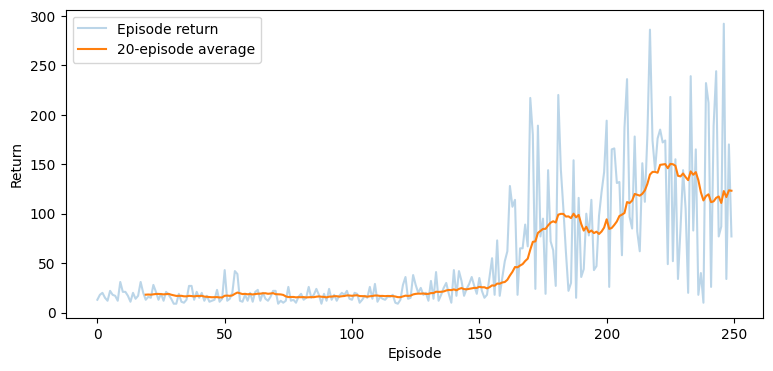

In [18]:
plt.figure(figsize=(9,4))
plt.plot(reward_history[:250],alpha=.3,label='Episode return')
if len(reward_history[:250])>=20:
    plt.plot(np.arange(19,len(reward_history[:250])),np.convolve(reward_history[:250],np.ones(20)/20,'valid'),label='20-episode average')
plt.xlabel('Episode');plt.ylabel('Return');plt.legend();plt.show()

# 강사님 코드

In [19]:
def train_cartpole(episodes=500, double=False, seed=2026):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    env = gym.make('CartPole-v1')
    env.action_space.seed(seed)
    online = QNetwork().to(DEVICE)
    target = QNetwork().to(DEVICE)
    target.load_state_dict(online.state_dict())
    target.eval()
    optimizer = optim.Adam(online.parameters(), lr=5e-4)
    replay = ReplayBuffer()
    returns = []
    losses = []
    steps = 0
    for episode in range(episodes):
        state, _ = env.reset(seed=seed+episode)
        total = 0.0
        for t in range(500):
            # 초반에는 무작위 행동을 많이 하고, 이후 점차 학습된 행동을 활용
            epsilon = max(0.05, 1.0-steps/12000)
            if random.random() < epsilon:
                action = env.action_space.sample()
            else:
                with torch.no_grad():
                    tensor = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                    action = int(online(tensor).argmax(dim=1).item())
            next_state, reward, terminated, truncated, _ = env.step(action)
            replay.add(state, action, reward, next_state, terminated)
            state = next_state
            total += reward
            steps += 1
            # 경험이 1000개 이상 쌓인 후 4스텝마다 dqn_update()로 신경망을 학습
            if len(replay) >= 1000 and steps % 4 == 0:
                losses.append(dqn_update(online, target, replay, optimizer, double=double))
            # 500스텝마다 online의 가중치를 target에 복사. 역전파가 아닌 가중치 동기화
            if steps % 500 == 0:
                target.load_state_dict(online.state_dict())
            if terminated or truncated: break
        returns.append(total)
        if (episode+1) % 50 == 0:
            print(f'{episode+1:3d}회 | 최근 20회 평균 보상: {np.mean(returns[-20:]):.1f}')
    env.close()
    return online, returns, losses

In [20]:
import random
import numpy as np


trained_q, train_returns, train_losses = train_cartpole(episodes=1000)

 50회 | 최근 20회 평균 보상: 26.6
100회 | 최근 20회 평균 보상: 22.5
150회 | 최근 20회 평균 보상: 31.5
200회 | 최근 20회 평균 보상: 93.0
250회 | 최근 20회 평균 보상: 197.5
300회 | 최근 20회 평균 보상: 170.3
350회 | 최근 20회 평균 보상: 132.0
400회 | 최근 20회 평균 보상: 112.9
450회 | 최근 20회 평균 보상: 89.2
500회 | 최근 20회 평균 보상: 46.9
550회 | 최근 20회 평균 보상: 119.2
600회 | 최근 20회 평균 보상: 125.3
650회 | 최근 20회 평균 보상: 128.3
700회 | 최근 20회 평균 보상: 150.6
750회 | 최근 20회 평균 보상: 186.3
800회 | 최근 20회 평균 보상: 243.8
850회 | 최근 20회 평균 보상: 454.8
900회 | 최근 20회 평균 보상: 452.2
950회 | 최근 20회 평균 보상: 108.9
1000회 | 최근 20회 평균 보상: 71.0


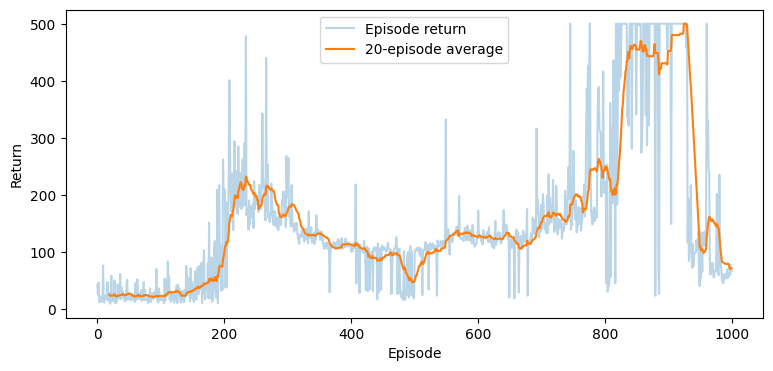

In [21]:
plt.figure(figsize=(9,4))
plt.plot(train_returns,alpha=.3,label='Episode return')
if len(train_returns)>=20:
    plt.plot(np.arange(19,len(train_returns)),np.convolve(train_returns,np.ones(20)/20,'valid'),label='20-episode average')
plt.xlabel('Episode');plt.ylabel('Return');plt.legend();plt.show()

In [22]:
def evaluate_cartpole(model, episodes=10, seed=9000):
    env = gym.make('CartPole-v1')
    scores = []
    model.eval()
    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep)
        total = 0
        while True:
            with torch.no_grad():
                x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                action = int(model(x).argmax(dim=1).item())
            state, r, terminated, truncated, _ = env.step(action)
            total += r
            if terminated or truncated: break
        scores.append(total)
    env.close()
    return scores

In [23]:
evaluate_cartpole(online)

[100.0, 100.0, 95.0, 97.0, 96.0, 102.0, 97.0, 96.0, 98.0, 95.0]

# 3. Policy Gradient
```
달리는 캐릭터 앞에 장애물이 있음(가능한 행동은 0=대기, 1=점프)
- 점프해서 장애물을 피함 > 좋은 결과를 경험
- 비슷한 상황을 반복 학습한 뒤 > 점프 90%, 대기 10%
```

> 정책은 '항상 점프'가 아님. 장애물이 멀면 대기가 좋을 수 있고, 가까우면 점프가 좋을 수 있음. 따라서 신경망은 현재 상태를 입력받아 행동별 확률을 출력

In [24]:
before = np.array([0.5, 0.5])
after  = np.array([0.1, 0.9])
for name, p in [('학습 전', before), ('학습 후(가상)', after)]:
    print(f'{name}: 대기 {p[0]*100:.0f}%, 점프 {p[1]*100:.0f}%, 합계 {p.sum():.1f}')

학습 전: 대기 50%, 점프 50%, 합계 1.0
학습 후(가상): 대기 10%, 점프 90%, 합계 1.0


### DQN vs 정책 신경망
- DQN: 행동의 예상 점수를 계산하고 높은 쪽으로 고름. 예) 현재 상태 > 신경망 > [대기 Q=2, 점프=6]
- 정책 신경망: 행동을 선택할 확률을 계산하고 그 확률에 따라 행동을 뽑을 수 있음. 예) 현재 상태 > 신경망 > [대기 20%, 점프 80%]

> 둘 다 신경망 가중치를 실제로 학습. 다만 출력의 의미와 학습 목표가 다름. DQN에서 $\epsilon$-greedy는 탐험을 위한 별도 규칙이지만, 정책 신경망은 행동 확률 자체를 배움

> 정책 기반이라고 해서 항상 무작위 행동만 하는 것은 아님. 평가할 때는 가장 확률이 높은 행동을 선택하기도 함.

### 학습의 순서
1. 현재 상황 관측. 예) 장애물 거리, 캐릭터 속도
2. 정책 신경망이 확률 계산. 예) 대기 40%, 점프 60%
3. 행동 선택. 예) 이번에는 점프
4. 실행. 예) 장애물을 피해서 보상 + 
5. 경험으로 학습 신호 만들기. 예) 이번 행동이 좋은 결과와 연결됐다는 정보
6. 손실함수 계산/역전파/가중치 수정. 예) 비슷한 상황에서 점프 확률을 높이는 방향으로 학습할 수 있음
7. 다시 게임 실행. 예) 많은 경험을 반복하며 정책 개선

# 4. Actor Critic
```
1. 캐릭터가 한 판을 끝까지 플레이함
2. 어떤 행동을 했고, 어떤 보상을 받았는지 기록
3. 그 시점 이후 얻은 보상(리턴)을 이용해 행동 확률을 조정
```
- 위 내용이 reinfoce의 핵심
- 성공에 이르는 과정의 행동들을 학습에 반영. 예) 5번 점프하고 스테이지를 모두 클리어 함
- 한 판이 끝나야 업데이트하는 기본형은 보상 변동이 커서 학습이 불안정할 수 있음
- 잘 했는지 판단하는 기준이 부족 \> Actor-Critic의 등장

- Actor: 지금 어떤 행동을 할지 정함. `ex) 점프 70%, 대기 30%`
- Critic: 현재 상황이 앞으로 얼마나 유리한지 평가. 예) V(s)=5

> 예상보다 결과가 좋으면 > 선택한 행동의 확률을 높이는 학습 신호

> 예상보다 결과가 나쁘면 > 선택한 확률을 낮추는 학습 신호

> Critic의 예측은 정답이 아니라 학습중이 추정치, 평가도 틀릴 수 있음

### Advantage
```
A(s, a) = Q(s, a) - V(s)
```
- Q: 특정 행동의 예상 가치
- V: 그 상태에서 정책을 따를 때의 평균적인 예상 가치
- Actor-Critic 코드에서는 $r + \gamma V(s') - V(s)$ 같은 TD 오차를 Advantage의 추정값으로 사용
- Advantage는 받은 보상 r이 아닌, 기대와 비교한 차이

In [25]:
expected = 5.0
for name, estimated_action_value in [('점프', 8.0), ('대기', 3.0)]:
    advantage = estimated_action_value - expected
    print(f'{name}: 행동가치 {estimated_action_value:.1f} - 상태가치 {expected:.1f} = Advantage {advantage:+.1f}')

점프: 행동가치 8.0 - 상태가치 5.0 = Advantage +3.0
대기: 행동가치 3.0 - 상태가치 5.0 = Advantage -2.0


In [26]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cuda


In [27]:
from torch.distributions import Categorical, Normal

class PolicyNet(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 64),
            nn.Tanh(),
            nn.Linear(64, n_actions)
        )
    def forward(self, x):
        return self.net(x)

In [28]:
policy_demo = PolicyNet().to(DEVICE)
state_demo = torch.tensor([[0.0, 0.1, 0.02, -0.03]], dtype=torch.float32, device=DEVICE)
logits = policy_demo(state_demo)

# Categorical: 0, 1 처럼 이산 행동의 확률 분포
# Normal: 연속 행동의 정규 분포
# logits는 확률 이전의 점수 > softmax를 적용하면 합계가 1인 확률 > Categorical로 실제 행동을 추첨
dist = Categorical(logits=logits)
a = dist.sample()

print('logits: ', logits.detach().cpu().numpy())
print('확률: ', dist.probs.detach().cpu().numpy())
print('행동: ', a.item(), ' | log_prob: ', dist.log_prob(a).item())

logits:  [[-0.31160554  0.01340485]]
확률:  [[0.41945514 0.5805448 ]]
행동:  1  | log_prob:  -0.5437882542610168


## 한 에피소드가 끝난 뒤 학습

- 순서: reset() > 행동 샘플 > step > (log_prob, reward) 저장 > 종료 > G_t 계산 > loss.backward() > optimizer.step()
- 미래 보상을 실제 에피소드 결과에서 계산하므로 신경망으로 다음 상태 가치를 부트스트랩하지 않음
- 에피소드 전체를 기다려야 하고 결과 변동이 큼
- 예) 보상이 [1, 1, 1], γ=0.9이면 마지막 시점 G₂=1, G₁=1+0.9×1=1.9, G₀=1+0.9×1.9=2.71
- 첫 행동은 이후 보상까지 반영

In [29]:
def discounted_returns(rewards,gamma=0.99):
    out=[]; running=0.0
    for r in reversed(rewards):
        running=float(r)+gamma*running
        out.append(running)
    return list(reversed(out))
print('예시:',discounted_returns([1,1,1],gamma=0.9))

예시: [2.71, 1.9, 1.0]


In [30]:
DTYPE = torch.float32

def train_reinforce(episodes=250, seed=2026, gamma=0.99, lr=1e-3):
    torch.manual_seed(seed)
    env = gym.make('CartPole-v1')
    net = PolicyNet().to(DEVICE)
    optimizer = optim.Adam(net.parameters(), lr=lr)
    scores = []

    for ep in range(episodes):
      state, _ = env.reset(seed=seed+ep)
      logps = []
      rewards = []

      for t in range(500):
        state = torch.tensor(state, dtype=DTYPE, device=DEVICE)

        # action logits (2,)
        logits = net(state)

        # 행동 확률 분포
        dist = Categorical(logits=logits)

        # 행동 [0, 1]
        action = dist.sample()
        # 행동의 확률을 로그로 저장 -> 
        logps.append(dist.log_prob(action))
        # print(type(action))
        
        next_state, reward, terminated, truncated, _ = env.step(action.item())

        rewards.append(reward)

        if terminated or truncated:
            break

        state = next_state

      # 1번부터 마지막까지 행동에 대한 보상 받기
      returns = discounted_returns(rewards)
      # 텐서로 변환
      returns = torch.tensor(
          returns, dtype=DTYPE, device=DEVICE
      )

      # 보상 정규화
      if len(returns) > 1:
            returns = (returns-returns.mean()) / (returns.std(unbiased=False)+1e-8)
      # 손실함수
      # stack을 통해서 list[Tensor(Size=[])]을 (n,) 형태로 바꿔주기
      logps = torch.stack(logps)
      # 확신이 높을수록 좋게 만들기
      # logp는 1일 경우 0, 0에 가까워질수록 큰 음수가 됨.
      loss = -(logps * returns).sum()

      # 학습
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

      scores.append(sum(rewards))
      
      if (ep+1)%30==0:
         print(f'REINFORCE {ep+1}/{episodes} " \
                "| 최근 20회 평균 {np.mean(scores[-20:]):.1f}')
      """
      1. tensor로 저장
      2. Categorical 사용
      3. sample 뽑기
      4. 4개의 상태 저장
      5. 학습
      """

    env.close()
    return net, scores

In [44]:
net, scores = train_reinforce(500)

REINFORCE 30/500 "                 "| 최근 20회 평균 22.6
REINFORCE 60/500 "                 "| 최근 20회 평균 36.2
REINFORCE 90/500 "                 "| 최근 20회 평균 43.5
REINFORCE 120/500 "                 "| 최근 20회 평균 56.8


KeyboardInterrupt: 

REINFORCE 30/500 "                 "| 최근 20회 평균 22.6
REINFORCE 60/500 "                 "| 최근 20회 평균 36.2
REINFORCE 90/500 "                 "| 최근 20회 평균 43.5
REINFORCE 120/500 "                 "| 최근 20회 평균 56.8
REINFORCE 150/500 "                 "| 최근 20회 평균 77.5
REINFORCE 180/500 "                 "| 최근 20회 평균 112.0
REINFORCE 210/500 "                 "| 최근 20회 평균 148.7
REINFORCE 240/500 "                 "| 최근 20회 평균 161.1
REINFORCE 270/500 "                 "| 최근 20회 평균 190.6
REINFORCE 300/500 "                 "| 최근 20회 평균 246.2
REINFORCE 330/500 "                 "| 최근 20회 평균 230.9
REINFORCE 360/500 "                 "| 최근 20회 평균 197.2
REINFORCE 390/500 "                 "| 최근 20회 평균 376.8
REINFORCE 420/500 "                 "| 최근 20회 평균 300.9
REINFORCE 450/500 "                 "| 최근 20회 평균 300.4
REINFORCE 480/500 "                 "| 최근 20회 평균 395.1


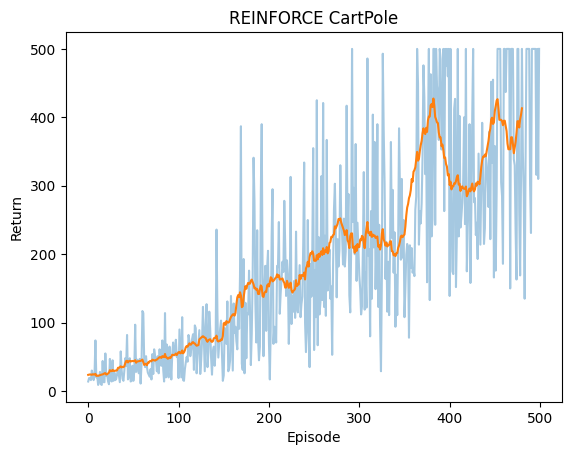

In [45]:
reinforce_model,reinforce_scores=train_reinforce(episodes=500)
plt.plot(reinforce_scores,alpha=.4)
if len(reinforce_scores)>=20:plt.plot(np.convolve(reinforce_scores,np.ones(20)/20,mode='valid'))
plt.title('REINFORCE CartPole');plt.xlabel('Episode');plt.ylabel('Return');plt.show()

- Critic: 현재 상황이 앞으로 얼마나 유리한지 평가. 예) V(s)=5

> 예상보다 결과가 나쁘면 > 선택한 행동의 확률을 낮추는 학습 신호

> Critic의 예측은 정답이 아니라 학습 중인 추정치. 평가도 틀릴 수 있음


#### 장애물 피하기 게임
1. 캐릭터 앞에 장애물이 나타남. (state, 상태)
2. Actor가 점프 70%, 대기 30%를 출력하고 행동을 하나 뽑음. (policy, 정책)
3. Critic은 현재 상황에서 앞으로 얻을 할인된 보상의 기대값을 예측함. 예: V(s) = 4
4. 실제로 행동한 뒤 보상 r과 다음 상태 s'을 관찰함
5. Critic의 새 예측을 이용해 TD 오차 $\delta$를 계산하고, Actor와 Critic을 각각 학습

> Critic이 정답을 아는 것은 아님. Critic도 경험을 통해 예측을 고쳐 나감

1. Actor의 출력
- 행동을 하는 선택 확률 출력 -> 행동들의 확률 분포를 출력
- DQN의 Q(s, a)는 행동별 가치, Actor의 $\pi(a|s)$는 행동별 확률이므로 서로 다름
2. Critic의 출력
- 상태 가치 V(s)를 출력. 
- 현재 상태에서 정책을 따를 때 앞으로 얻을 할인된 보상의 기댓값

$$
\delta = r + \gamma(1-done)V(s') - V(s)
$$

> $\delta$는 TD 오차. 새로 계산한 TD 목표 - Critic이 이전에 예측한 현재 가치 



- 게임이 끝나지 않았다면(done=0)

$$\delta = r + \gamma V(s') - V(s)$$

- 게임이 끝나지 않았다면(done=1)

$$\delta = r - V(s)$$



## 게임이 아직 끝나지 않았고, 아래와 내용을 참고
- 현재 가치 V(s) = 4
- 점프 직후 보상 r = 1
- 다음 상태 가치 V(s') = 6
- 할인율 0.9
- done = 0

> TD target = 6.4

> TD Error = 2.4

> Critic이 예상한 4보다 TD 목표 6.4가 높음. Actor은 방금 선택한 행동(점프)의 확률을 높이는 방향으로, Critic은 4라는 예측을 6.4에 가깝게 만드는 방향으로 학습

> 2.4는 확률이 2.4% 증가한다는 뜻은 아님. 실제 변화량은 신경망과 학습률에 따라 달라짐. Critic의 예측이 부정확할 수 있으므로 정답이 아니라 학습 신호

$$
L_{actor}=-\log\pi(a|s)\,\mathrm{stopgrad}(\delta)
$$

$$
L_{critic}=(V(s)-\mathrm{stopgrad}(r+\gamma(1-done)V(s')))^2
$$

- $\operatorname{stopgrad}$: 해당 값을 상수처럼 취급하여 그 경로로 역전파하지 않는다는 의미(detach(), torch.no_grad())
- 

In [33]:
def td_error(value, reward, next_value, gamma=0.9, done=False):
    target = reward + gamma * (1 - int(done)) * next_value
    delta = target - value
    return target, delta

cases = [
    ("예상보다 좋음", 4, 1, 6, 0.9, False),
    ("예상보다 나쁨", 5, 2, 4, 0.5, False),
    ("종료 상태", 4, 1, 100, 0.9, True),
]
for name, v, r, next_v, gamma, done in cases:
    target, delta = td_error(v, r, next_v, gamma, done)
    print(f"{name}: TD 목표={target:.2f}, 현재 예측={v:.2f}, δ={delta:+.2f}")

예상보다 좋음: TD 목표=6.40, 현재 예측=4.00, δ=+2.40
예상보다 나쁨: TD 목표=4.00, 현재 예측=5.00, δ=-1.00
종료 상태: TD 목표=1.00, 현재 예측=4.00, δ=-3.00


In [82]:
class ActorCriticNet(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(obs_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 128),
            nn.Tanh()
        )
        self.actor = nn.Linear(128, n_actions)
        self.critic = nn.Linear(128, 1)

    def forward(self, x):
        h = self.body(x)
        return self.actor(h), self.critic(h).squeeze(-1)    

In [35]:
ac_demo = ActorCriticNet().to(DEVICE)
lg, val = ac_demo(state_demo)
print('Actor logits: ', lg.shape, 'Critic V(s): ', val.shape)

Actor logits:  torch.Size([1, 2]) Critic V(s):  torch.Size([1])


In [36]:
import torch.nn.functional as F

ac = ActorCriticNet().to(DEVICE)
opt = optim.Adam(ac.parameters(), lr=1e-3)
s = torch.zeros((1, 4), device=DEVICE)
s2 = torch.tensor([[0.02, 0.1, -0.03, 0.02]], device=DEVICE)

logits, value = ac(s)
dist = Categorical(logits=logits)
a = dist.sample()

with torch.no_grad():
    _, next_value = ac(s2)
    td_target = torch.tensor([1.0], device=DEVICE) + 0.99*next_value

# delta
advantage = td_target - value
# Actor Loss
actor_loss = -(dist.log_prob(a) * advantage.detach()).mean()

# Critic Loss
critic_loss = F.mse_loss(value, td_target)

# loss 병합
loss = actor_loss + 0.5 * critic_loss
opt.zero_grad()
loss.backward()
opt.step()
print('선택 행동:',a.item(),'TD 목표:',td_target.item(),'Advantage:',advantage.item(),'Loss:',loss.item())

선택 행동: 0 TD 목표: 1.2189640998840332 Advantage: 1.0006285905838013 Loss: 1.2559750080108643


In [37]:
print('선택 행동:',a.item(),'TD 목표:',td_target.item(),'Advantage:',advantage.item(),'Loss:',loss.item())

선택 행동: 0 TD 목표: 1.2189640998840332 Advantage: 1.0006285905838013 Loss: 1.2559750080108643


### REINFORCE CartPole을 Actor-Critic으로 변경

- REINFORCE는 에피소드가 끝난 뒤 할인 리턴을 계산했지만, Actor-Critic은 매 스텝 TD 오차로 업데이트
- PolicyNet 대신 Actor의 logits 2개 + Critic의 상태 가치 1개를 출력하는 ActorCriticNet을 사용
- 학습 보상 곡선을 REINFORCE와 비교함

1. ActorCriticNet을 이용해서 행동 확률과 상태 가치 V(s)를 출력
2. Categorical(logits=logitis)로 행동을 샘플링하고 환경에서 한 스텝을 실행
3. 500개 에피소드 동안 학습하고, 각 에피소드 보상과 최근 20회 이동평균을 그림
4. 이미 학습한 reinforce_scores와 두 학습 곡선을 비교

In [40]:
type(reward_history), len(reward_history)

(list, 500)

In [79]:
EPISODE = 1500
seed=42
DTYPE = torch.float32
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
env = gym.make('CartPole-v1')
env.action_space.seed(seed)
ac = ActorCriticNet().to(DEVICE)
opt = optim.Adam(ac.parameters(), lr=1e-3)
GAMMA = 0.99

ac_reward_history = []

print(DEVICE)

for epi in range(1, EPISODE+1):

  obs, _ = env.reset(seed=seed+epi)

  # 최초 상태  초기화
  total_reward = 0
  state = torch.tensor(obs, dtype=DTYPE, device=DEVICE)
  # with torch.no_grad():
  #   logits, value = ac(state)
  #   dist = Categorical(logits=logits)
  #   action = dist.sample()

  for t in range(500):
    # 현재 상태에서 다음 행동 뽑기
    logits, value = ac(state)
    dist = Categorical(logits=logits)
    action = dist.sample()

    # 다음 상태 뽑기
    next_state, reward, term, trunc, _ = env.step(action.item())
    total_reward += float(reward)
    done = int(term or trunc)
    next_state = torch.tensor(next_state, dtype=DTYPE, device=DEVICE)

    # TD Target 계산하기
    with torch.no_grad():
      # 다음 타깃 추측 상태 가치
      _, next_value = ac(next_state)
      # 타깃으로 취급할 상태 가치
      td_target = reward + (1-done) * GAMMA * next_value

    # 오차값
    # delta값
    advantage = td_target - value
    # actor
    actor_loss = -(dist.log_prob(action) * advantage.detach()) 

    # critic loss
    critic_loss = F.mse_loss(value, td_target)

    loss = actor_loss + 0.5 * critic_loss

    opt.zero_grad()
    loss.backward()
    opt.step()

    # 다음 상태 비교를 위한 갱신
    state = next_state

    if done:
      break

  ## 에피소드 종료  
  ac_reward_history.append(total_reward)


  if epi % 50 == 0: 
    print(f"episode: {epi} | [{epi-49}~{epi} average] - {np.mean(ac_reward_history[epi-49:]):.2f} ")

cuda
episode: 50 | [1~50 average] - 10.51 
episode: 100 | [51~100 average] - 11.98 
episode: 150 | [101~150 average] - 25.73 
episode: 200 | [151~200 average] - 61.86 
episode: 250 | [201~250 average] - 61.69 
episode: 300 | [251~300 average] - 60.10 
episode: 350 | [301~350 average] - 76.51 
episode: 400 | [351~400 average] - 77.92 
episode: 450 | [401~450 average] - 67.31 
episode: 500 | [451~500 average] - 92.08 
episode: 550 | [501~550 average] - 306.00 
episode: 600 | [551~600 average] - 270.82 
episode: 650 | [601~650 average] - 500.00 
episode: 700 | [651~700 average] - 484.82 


KeyboardInterrupt: 

In [50]:
type(reinforce_scores), len(reinforce_scores), np.mean(reinforce_scores),"\n", type(ac_reward_history), len(ac_reward_history), np.mean(ac_reward_history)

(list, 500, np.float64(187.974), '\n', list, 500, np.float64(155.332))

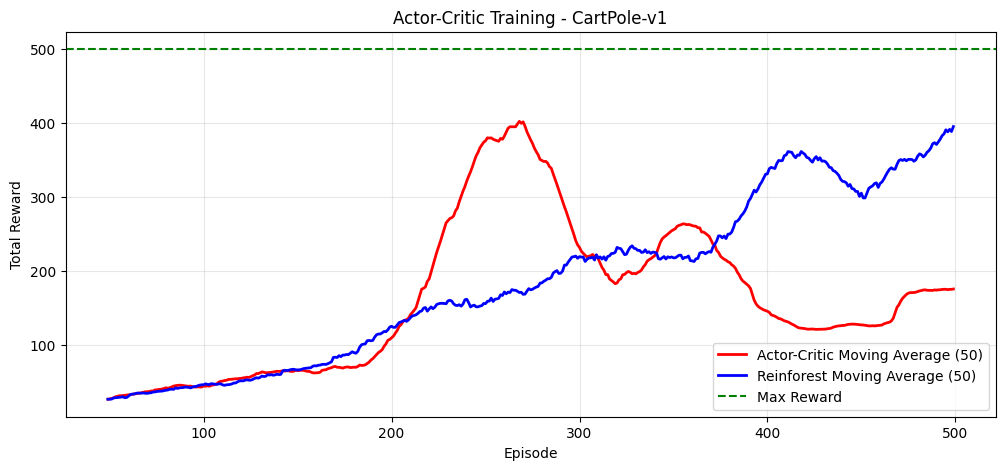

In [53]:
import matplotlib.pyplot as plt
import numpy as np

rewards_ac = np.array(ac_reward_history)
rewards_rf = np.array(reinforce_scores)

# 최근 50개 에피소드 이동평균
window = 50
moving_avg_ac = np.convolve(
    rewards_ac,
    np.ones(window) / window,
    mode="valid"
)

moving_avg_rf = np.convolve(
    rewards_rf,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(12, 5))

# plt.plot(rewards_ac, alpha=0.3, label="Episode Reward")
plt.plot(
    np.arange(window - 1, len(rewards_ac)),
    moving_avg_ac,
    color="red",
    linewidth=2,
    label="Actor-Critic Moving Average (50)"
)

plt.plot(
    np.arange(window - 1, len(rewards_rf)),
    moving_avg_rf,
    color="blue",
    linewidth=2,
    label="Reinforest Moving Average (50)"
)

plt.axhline(y=500, color="green", linestyle="--", label="Max Reward")

plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Actor-Critic Training - CartPole-v1")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [84]:
EPISODE = 500
seed=42
DTYPE = torch.float32
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
env = gym.make('CartPole-v1')
env.action_space.seed(seed)
ac = ActorCriticNet().to(DEVICE)
opt = optim.Adam(ac.parameters(), lr=5e-4)
GAMMA = 0.9

ac_reward_history = []

print(DEVICE)

for epi in range(1, EPISODE+1):

  obs, _ = env.reset(seed=seed+epi)

  # 최초 상태  초기화
  total_reward = 0
  state = torch.tensor(obs, dtype=DTYPE, device=DEVICE)
  # with torch.no_grad():
  #   logits, value = ac(state)
  #   dist = Categorical(logits=logits)
  #   action = dist.sample()

  for t in range(500):
    # 현재 상태에서 다음 행동 뽑기
    logits, value = ac(state)
    dist = Categorical(logits=logits)
    action = dist.sample()

    # 다음 상태 뽑기
    next_state, reward, term, trunc, _ = env.step(action.item())
    total_reward += float(reward)
    done = int(term or trunc)
    next_state = torch.tensor(next_state, dtype=DTYPE, device=DEVICE)

    # TD Target 계산하기
    with torch.no_grad():
      # 다음 타깃 추측 상태 가치
      _, next_value = ac(next_state)
      # 타깃으로 취급할 상태 가치
      td_target = reward + (1-int(term)) * GAMMA * next_value

    # 오차값
    # delta값
    advantage = td_target - value
    # actor
    actor_loss = -(dist.log_prob(action) * advantage.detach()) 

    # critic loss
    critic_loss = F.mse_loss(value, td_target)

    loss = actor_loss + 0.5 * critic_loss

    opt.zero_grad()
    loss.backward()
    opt.step()

    # 다음 상태 비교를 위한 갱신
    state = next_state

    if done:
      break

  ## 에피소드 종료  
  ac_reward_history.append(total_reward)


  if epi % 50 == 0: 
    print(f"episode: {epi} | [{epi-49}~{epi} average] - {np.mean(ac_reward_history[epi-49:]):.2f} ")

cuda
episode: 50 | [1~50 average] - 38.45 
episode: 100 | [51~100 average] - 184.90 
episode: 150 | [101~150 average] - 294.37 
episode: 200 | [151~200 average] - 237.96 
episode: 250 | [201~250 average] - 192.22 
episode: 300 | [251~300 average] - 117.29 
episode: 350 | [301~350 average] - 149.31 
episode: 400 | [351~400 average] - 143.49 
episode: 450 | [401~450 average] - 153.39 
episode: 500 | [451~500 average] - 171.96 


In [58]:
EPISODE = 500
seed=42
DTYPE = torch.float32
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
env = gym.make('CartPole-v1')
env.action_space.seed(seed)
ac = ActorCriticNet().to(DEVICE)
opt = optim.Adam(ac.parameters(), lr=1e-3)
GAMMA = 0.99

ac_reward_history = []

print(DEVICE)

for epi in range(1, EPISODE+1):

  obs, _ = env.reset(seed=seed+epi)

  # 최초 상태  초기화
  total_reward = 0
  state = torch.tensor(obs, dtype=DTYPE, device=DEVICE)
  # with torch.no_grad():
  #   logits, value = ac(state)
  #   dist = Categorical(logits=logits)
  #   action = dist.sample()

  for t in range(500):
    # 현재 상태에서 다음 행동 뽑기
    logits, value = ac(state)
    dist = Categorical(logits=logits)
    action = dist.sample()

    # 다음 상태 뽑기
    next_state, reward, term, trunc, _ = env.step(action.item())
    total_reward += float(reward)
    done = int(term or trunc)
    next_state = torch.tensor(next_state, dtype=DTYPE, device=DEVICE)

    # TD Target 계산하기
    with torch.no_grad():
      # 다음 타깃 추측 상태 가치
      _, next_value = ac(next_state)
      # 타깃으로 취급할 상태 가치
      td_target = reward + (1-done) * GAMMA * next_value

    # 오차값
    # delta값
    advantage = td_target - value
    # actor
    actor_loss = -(dist.log_prob(action) * advantage.detach()) 

    # critic loss
    critic_loss = F.mse_loss(value, td_target)

    loss = actor_loss + 0.5 * critic_loss

    opt.zero_grad()
    loss.backward()
    opt.step()

    # 다음 상태 비교를 위한 갱신
    state = next_state

    if done:
      break

  ## 에피소드 종료  
  ac_reward_history.append(total_reward)


  if epi % 50 == 0: 
    print(f"episode: {epi} | [{epi-49}~{epi} average] - {np.mean(ac_reward_history[epi-49:]):.2f} ")

cuda
episode: 50 | [1~50 average] - 10.51 
episode: 100 | [51~100 average] - 11.98 
episode: 150 | [101~150 average] - 25.73 
episode: 200 | [151~200 average] - 61.86 
episode: 250 | [201~250 average] - 61.69 
episode: 300 | [251~300 average] - 60.10 
episode: 350 | [301~350 average] - 76.51 
episode: 400 | [351~400 average] - 77.92 
episode: 450 | [401~450 average] - 67.31 
episode: 500 | [451~500 average] - 92.08 


In [81]:
EPISODE = 500
seed=42
DTYPE = torch.float32
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
env = gym.make('CartPole-v1')
env.action_space.seed(seed)
ac = ActorCriticNet().to(DEVICE)
with torch.no_grad():
    for param in ac.parameters():
        param.zero_()
opt = optim.Adam(ac.parameters(), lr=3e-4)
GAMMA = 0.75

ac_reward_history = []

print(DEVICE)

for epi in range(1, EPISODE+1):

  obs, _ = env.reset(seed=seed+epi)

  # 최초 상태  초기화
  total_reward = 0
  state = torch.tensor(obs, dtype=DTYPE, device=DEVICE)
  # with torch.no_grad():
  #   logits, value = ac(state)
  #   dist = Categorical(logits=logits)
  #   action = dist.sample()

  for t in range(500):
    # 현재 상태에서 다음 행동 뽑기
    logits, value = ac(state)
    dist = Categorical(logits=logits)
    action = dist.sample()

    # 다음 상태 뽑기
    next_state, reward, term, trunc, _ = env.step(action.item())
    total_reward += float(reward)
    done = int(term or trunc)
    next_state = torch.tensor(next_state, dtype=DTYPE, device=DEVICE)

    # TD Target 계산하기
    with torch.no_grad():
      # 다음 타깃 추측 상태 가치
      _, next_value = ac(next_state)
      # 타깃으로 취급할 상태 가치
      td_target = reward + (1-done) * GAMMA * next_value

    # 오차값
    # delta값
    advantage = td_target - value
    # actor
    actor_loss = -(dist.log_prob(action) * advantage.detach()) 

    # critic loss
    critic_loss = F.mse_loss(value, td_target)

    loss = actor_loss + 0.5 * critic_loss

    opt.zero_grad()
    loss.backward()
    opt.step()

    # 다음 상태 비교를 위한 갱신
    state = next_state

    if done:
      break

  ## 에피소드 종료  
  ac_reward_history.append(total_reward)


  if epi % 50 == 0: 
    print(f"episode: {epi} | [{epi-49}~{epi} average] - {np.mean(ac_reward_history[epi-49:]):.2f} ")

cuda
episode: 50 | [1~50 average] - 22.16 
episode: 100 | [51~100 average] - 21.71 
episode: 150 | [101~150 average] - 21.67 
episode: 200 | [151~200 average] - 19.94 
episode: 250 | [201~250 average] - 18.96 
episode: 300 | [251~300 average] - 23.47 
episode: 350 | [301~350 average] - 21.20 
episode: 400 | [351~400 average] - 20.06 
episode: 450 | [401~450 average] - 22.08 
episode: 500 | [451~500 average] - 20.71 


# 강사님 코드

In [75]:
def train_actor_critic_answer(episodes=250, seed=2026, gamma=0.9, lr=7e-4):
    torch.manual_seed(seed)
    env = gym.make('CartPole-v1')
    model = ActorCriticNet().to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scores = []

    for ep in range(episodes):
        state, _ = env.reset(seed=seed + ep)
        score = 0.0
        for t in range(500):
            x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
            # print(x.shape)
            logits, value = model(x) # Actor logits, Critic V(s)
            dist = Categorical(logits=logits)
            action = dist.sample() # 0: 왼쪽, 1: 오른쪽
            next_state, reward, terminated, truncated, _ = env.step(int(action.item()))

            with torch.no_grad():
                nx = torch.as_tensor(next_state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                _, next_value = model(nx)
                td_target = torch.tensor([reward], dtype=torch.float32, device=DEVICE) + gamma * (1.0 - float(terminated)) * next_value

            delta = td_target - value
            actor_loss = -(dist.log_prob(action) * delta.detach()).mean()
            critic_loss = F.mse_loss(value, td_target)
            loss = actor_loss + 0.5 * critic_loss

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            score += float(reward)
            state = next_state
            if terminated or truncated:
                break

        scores.append(score)
        if (ep + 1) % 30 == 0:
            print(f'Actor-Critic {ep + 1} / {episodes} | 최근 20회 평균 {np.mean(scores[-20:]):.1f}')

    env.close()
    return model, scores

Actor-Critic 30 / 250 | 최근 20회 평균 9.9
Actor-Critic 60 / 250 | 최근 20회 평균 11.1
Actor-Critic 90 / 250 | 최근 20회 평균 11.3
Actor-Critic 120 / 250 | 최근 20회 평균 20.8
Actor-Critic 150 / 250 | 최근 20회 평균 37.9
Actor-Critic 180 / 250 | 최근 20회 평균 60.3
Actor-Critic 210 / 250 | 최근 20회 평균 59.5
Actor-Critic 240 / 250 | 최근 20회 평균 49.2


c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 44540 (\N{HANGUL SYLLABLE GEUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 54924 (\N{HANGUL SYLLABLE HOE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\IPython\core\py

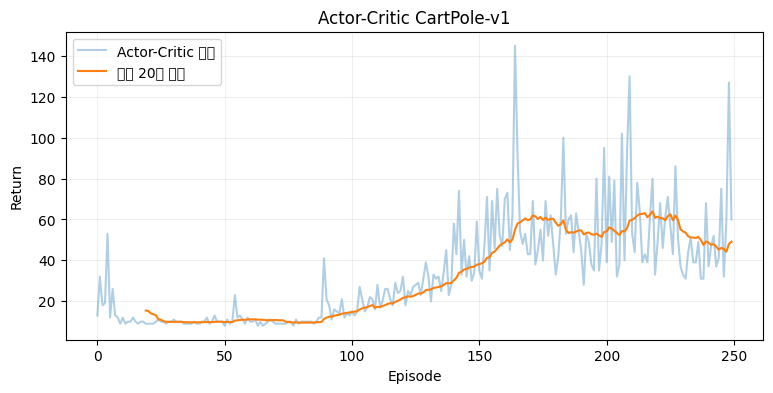

In [76]:
ac_cartpole_model, ac_cartpole_scores = train_actor_critic_answer()
plt.figure(figsize=(9, 4))
plt.plot(ac_cartpole_scores, alpha=0.35, label='Actor-Critic 보상')
if len(ac_cartpole_scores) >= 20:
    ma = np.convolve(ac_cartpole_scores, np.ones(20)/20, mode='valid')
    plt.plot(np.arange(19, len(ac_cartpole_scores)), ma, label='최근 20회 평균')
plt.xlabel('Episode'); plt.ylabel('Return'); plt.title('Actor-Critic CartPole-v1')
plt.legend(); plt.grid(alpha=0.2); plt.show()

c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 48372 (\N{HANGUL SYLLABLE BO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\LANG_CHAIN_2026\2026-05-19_KDT_lang_chain\.venv\Lib\site-packages\IPython\core\pylab

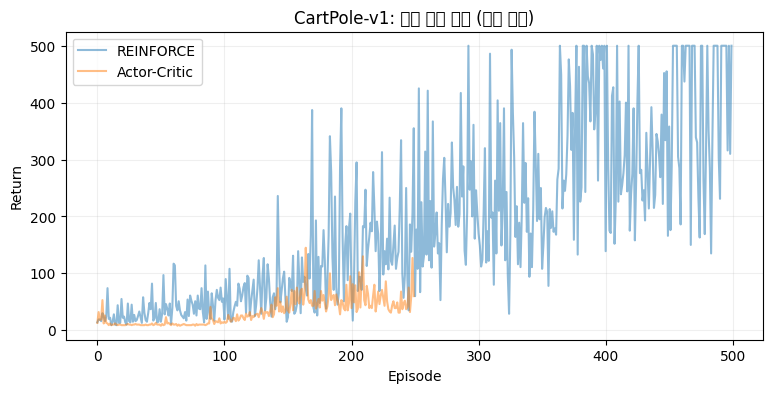

최근 20회 평균 REINFORCE: 413.2
최근 20회 평균 Actor-Critic: 49.1


In [74]:
plt.figure(figsize=(9, 4))
plt.plot(reinforce_scores, alpha=0.5, label='REINFORCE')
plt.plot(ac_cartpole_scores, alpha=0.5, label='Actor-Critic')
plt.xlabel('Episode'); plt.ylabel('Return')
plt.title('CartPole-v1: 학습 보상 비교 (단일 실행)')
plt.legend(); plt.grid(alpha=0.2); plt.show()
print('최근 20회 평균 REINFORCE:', round(float(np.mean(reinforce_scores[-20:])), 1))
print('최근 20회 평균 Actor-Critic:', round(float(np.mean(ac_cartpole_scores[-20:])), 1))

### REINFORCE vs Actor-Critic 비교

1. REINFORCE
- 에피소드가 끝난 뒤 누적보상을 계산
- 실제 경험에서 얻은 리턴을 이용해 정책을 학습
- 리턴의 분산은 클 수 있지만, Critic의 가치 예측 오차에 영향을 받지 않음

2. Actor-Critic
- 매 스텝 TD 오차를 계산
- Critic의 가치 예측을 이용해 Actor를 학습
- Critic의 예측이 부정확하면 Actor도 잘못된 방향으로 업데이트될 수 있음

### Actor-Critic의 성능을 늘리는 법
- 레이어 늘리기
- 학습률 낮추기
- 에피소드 늘리기

# Actor-Critic을 이용한 달 착륙 AI 개발

Gymnasium을 이용하여 우주선이 스스로 엔진을 제어하고 안전하게 착륙하도록 학습하는 강화학습 시스템 개발

In [ ]:
class ActorCriticNet(nn.Module):
    def __init__(self, obs_dim=8, n_actions=4):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(obs_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 256),
            nn.LayerNorm(256),
            nn.Tanh(),
            nn.Linear(256, 128),
        )
        self.actor = nn.Linear(128, n_actions)
        self.critic = nn.Linear(128, 1)

    def forward(self, x):
        h = self.body(x)
        return self.actor(h), self.critic(h).squeeze(-1)

### 1. 프로젝트 시나리오
- 달 표면에 착륙할 우주선은 처음에는 엔진을 언제 사용해야 하는지 알지 못함
- 너무 빠르게 하강하면 추락하고, 좌우 균형을 잡지 못하면 착륙 지점을 벗어날 수 있음
    - 우주선의 현재 위치와 속도를 분석
    - 우주선의 기울기와 회전 속도를 확인
    - 엔진을 사용하거나 사용하지 않는 행동을 선택
    - 행동 결과로 받은 보상을 이용하여 Actor와 Critic을 학습
    - 반복 학습을 통해 안전한 착륙을 시도

In [96]:
import gymnasium as gym


def train_ac_lunar_lander(episode=500, gamma=0.9, lr=5e-4, seed=42, max_step=500, dtype=DTYPE):
  env = gym.make("LunarLander-v3")#, render_mode="human")

  ac = ActorCriticNet(8, 4).to(DEVICE)
  device = next(ac.parameters()).device
  optimizer = optim.Adam(ac.parameters(), lr=lr)

  # 임시 형태 출력용
  flag=True

  reward_history = []

  for epi in range(1, episode+1):
    total_reward = 0
    state, info = env.reset(seed=42+epi)  

    for t in range(max_step):
      # 다음 행동 뽑기
      state = torch.as_tensor(state, dtype=dtype, device=device)
      if flag:
        flag=False
        print("state.shape", state.shape)
      logits, values = ac(state)
      dist = Categorical(logits=logits)
      action = dist.sample()
      next_state, reward, terminated, truncated, _ = env.step(int(action.item()))
      total_reward += float(reward)

      # 다음 진짜로 칠 상태 뽑아두기
      with torch.no_grad():
        _, next_values = ac(torch.as_tensor(next_state, dtype=dtype, device=device))
        td_target = reward + gamma*(1-terminated)*next_values

      # actor loss 구하기
      delta = td_target - values
      actor_loss = -(dist.log_prob(action)*delta.detach())

      # critic loss
      critic_loss = F.mse_loss(values, td_target)

      loss = critic_loss * 0.5 + actor_loss


      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

      state = next_state
      if terminated or truncated:
        break

    reward_history.append(total_reward)

    if epi % 50 == 0:
      print(f"episode: {epi}\t| {epi-49}~{epi} total reward mean \t| {np.mean(reward_history[epi-50:])}")

  return {
    "model": ac,
    "reward_history": reward_history,
    "config": {
      "seed": seed,
      "gamma": gamma,
      "learning_rate": lr,
      "episode": episode,
      "max_step": max_step
    }
  }


In [95]:
result = train_ac_lunar_lander()

state.shape torch.Size([8])
episode: 50	| 1~50 total reward mean 	| -531.1425946928483
episode: 100	| 51~100 total reward mean 	| -506.02050805241475
episode: 150	| 101~150 total reward mean 	| -589.8683963006561
episode: 200	| 151~200 total reward mean 	| -571.8060699465099
episode: 250	| 201~250 total reward mean 	| -591.9348405253332
episode: 300	| 251~300 total reward mean 	| -572.4369680013407
episode: 350	| 301~350 total reward mean 	| -543.223306994198
episode: 400	| 351~400 total reward mean 	| -592.7950066796221
episode: 450	| 401~450 total reward mean 	| -561.0757129511222
episode: 500	| 451~500 total reward mean 	| -560.9054835164108


In [97]:

import itertools
import torch
import pandas as pd
import numpy as np
from pathlib import Path

# 실험할 하이퍼파라미터
param_grid = {
    "gamma": [0.9, 0.95, 0.99],
    "lr": [1e-3, 5e-4, 1e-4],
}

# 모든 조합 생성
configs = [
    dict(zip(param_grid.keys(), values))
    for values in itertools.product(*param_grid.values())
]

# 결과 저장
results = []
save_dir = Path("ac_lunar_results")
save_dir.mkdir(exist_ok=True)

for i, config in enumerate(configs, start=1):

    print(f"\n[{i}/{len(configs)}] config: {config}")

    result = train_ac_lunar_lander(
        episode=500,
        gamma=config["gamma"],
        lr=config["lr"],
        seed=42,
        max_step=500
    )

    rewards = result["reward_history"]

    # 모델 및 학습 결과 저장
    torch.save({
        "model_state_dict": result["model"].state_dict(),
        "reward_history": rewards,
        "config": result["config"]
    }, save_dir / f"experiment_{i}.pt")

    # 실험 성능 요약
    results.append({
        "experiment": i,
        **config,
        "mean_reward": np.mean(rewards),
        "last_50_mean": np.mean(rewards[-50:]),
        "max_reward": np.max(rewards)
    })

# 데이터프레임 생성
df = pd.DataFrame(results)

# CSV 저장
df.to_csv(save_dir / "summary.csv", index=False)

display(df.sort_values("last_50_mean", ascending=False))



[1/9] config: {'gamma': 0.9, 'lr': 0.001}
state.shape torch.Size([8])
episode: 50	| 1~50 total reward mean 	| -435.235291554033
episode: 100	| 51~100 total reward mean 	| -509.87918538800363
episode: 150	| 101~150 total reward mean 	| -344.74634371085756
episode: 200	| 151~200 total reward mean 	| -169.17360099317258
episode: 250	| 201~250 total reward mean 	| -151.16174360717457
episode: 300	| 251~300 total reward mean 	| -136.45832582872362
episode: 350	| 301~350 total reward mean 	| -75.36145400211974
episode: 400	| 351~400 total reward mean 	| -89.46278523082654
episode: 450	| 401~450 total reward mean 	| -36.83043857007632
episode: 500	| 451~500 total reward mean 	| -7.934829874628113

[2/9] config: {'gamma': 0.9, 'lr': 0.0005}
state.shape torch.Size([8])
episode: 50	| 1~50 total reward mean 	| -277.90995224052557
episode: 100	| 51~100 total reward mean 	| -371.26986935959764
episode: 150	| 101~150 total reward mean 	| -583.5255088696717
episode: 200	| 151~200 total reward mean 	

,experiment,gamma,lr,mean_reward,last_50_mean,max_reward
1,2,0.90,0.0005,-236.182608,13.188712,262.347741
0,1,0.90,0.0010,-195.624400,-7.934830,255.910223
3,4,0.95,0.0010,-208.365959,-50.760416,215.534456
7,8,0.99,0.0005,-137.303731,-121.509406,55.544085
4,5,0.95,0.0005,-421.025281,-134.915015,55.544085
6,7,0.99,0.0010,-429.550286,-199.568366,40.031624
2,3,0.90,0.0001,-252.518192,-240.780833,39.690861
8,9,0.99,0.0001,-256.542962,-243.542183,16.045013
5,6,0.95,0.0001,-338.551183,-321.399996,13.257573


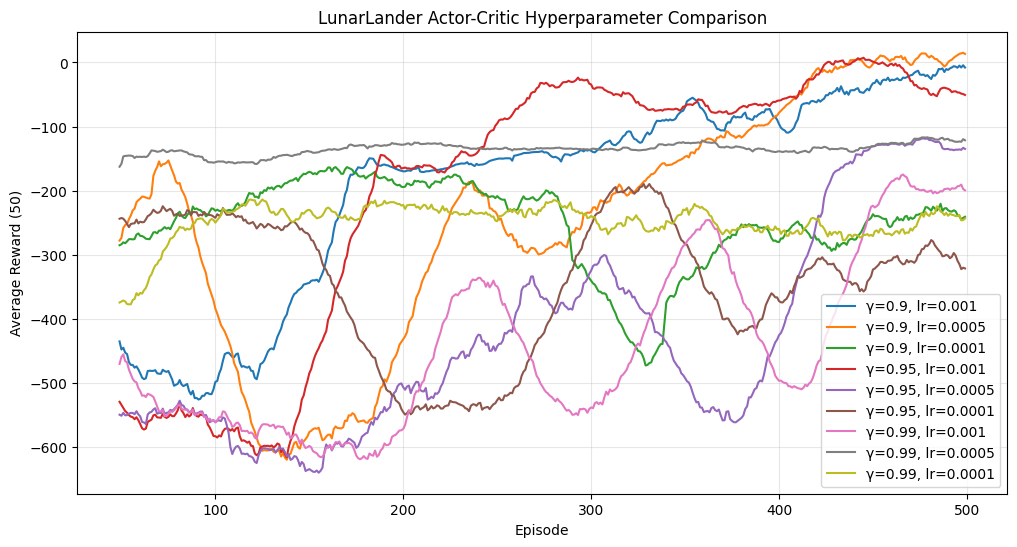

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for i in range(1, len(configs) + 1):
    checkpoint = torch.load(
        save_dir / f"experiment_{i}.pt",
        map_location="cpu",
        weights_only=True
    )

    rewards = checkpoint["reward_history"]
    config = checkpoint["config"]

    # 50 episode 이동평균
    moving_avg = np.convolve(
        rewards,
        np.ones(50) / 50,
        mode="valid"
    )

    plt.plot(
        np.arange(49, len(rewards)),
        moving_avg,
        label=f"γ={config['gamma']}, lr={config['learning_rate']}"
    )

plt.xlabel("Episode")
plt.ylabel("Average Reward (50)")
plt.title("LunarLander Actor-Critic Hyperparameter Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [103]:
result = train_ac_lunar_lander(gamma=0.99, lr=0.0001, episode=2000, max_step=1500)

state.shape torch.Size([8])
episode: 50	| 1~50 total reward mean 	| -269.32058401573425
episode: 100	| 51~100 total reward mean 	| -330.8790468656036
episode: 150	| 101~150 total reward mean 	| -398.44572924263827
episode: 200	| 151~200 total reward mean 	| -260.2462954408408
episode: 250	| 201~250 total reward mean 	| -257.38856671623654
episode: 300	| 251~300 total reward mean 	| -279.7179147848333
episode: 350	| 301~350 total reward mean 	| -269.29314238990537
episode: 400	| 351~400 total reward mean 	| -239.71435802840318
episode: 450	| 401~450 total reward mean 	| -226.59717632077545
episode: 500	| 451~500 total reward mean 	| -185.51686641804113
episode: 550	| 501~550 total reward mean 	| -139.027412071927
episode: 600	| 551~600 total reward mean 	| -144.5600029116436
episode: 650	| 601~650 total reward mean 	| -141.167783989463
episode: 700	| 651~700 total reward mean 	| -146.81596074944773
episode: 750	| 701~750 total reward mean 	| -151.450230510171
episode: 800	| 751~800 tota

In [104]:
result = train_ac_lunar_lander(gamma=0.9, lr=0.0005, episode=2000, max_step=1500)

state.shape torch.Size([8])
episode: 50	| 1~50 total reward mean 	| -280.3168247276751
episode: 100	| 51~100 total reward mean 	| -248.9448917876606
episode: 150	| 101~150 total reward mean 	| -150.96924451649417
episode: 200	| 151~200 total reward mean 	| -269.23675481500356
episode: 250	| 201~250 total reward mean 	| -152.95662430303435
episode: 300	| 251~300 total reward mean 	| -167.68312349995463
episode: 350	| 301~350 total reward mean 	| -125.81766083274968
episode: 400	| 351~400 total reward mean 	| -267.5623215024838
episode: 450	| 401~450 total reward mean 	| -208.64444402912923
episode: 500	| 451~500 total reward mean 	| -497.2404115458284
episode: 550	| 501~550 total reward mean 	| -587.3959934008786
episode: 600	| 551~600 total reward mean 	| -589.9525456231821
episode: 650	| 601~650 total reward mean 	| -578.3765241904318
episode: 700	| 651~700 total reward mean 	| -545.2743483709398
episode: 750	| 701~750 total reward mean 	| -549.9960681344506
episode: 800	| 751~800 tot

KeyboardInterrupt: 

In [ ]:
import gymnasium as gym


def train_ac_lunar_lander_with_entropy_coef(episode=500, gamma=0.9, lr=5e-4, seed=42, max_step=500, dtype=DTYPE):
  env = gym.make("LunarLander-v3")#, render_mode="human")

  ac = ActorCriticNet(8, 4).to(DEVICE)
  device = next(ac.parameters()).device
  optimizer = optim.Adam(ac.parameters(), lr=lr)

  # 임시 형태 출력용
  flag=True

  reward_history = []
  
  
  for epi in range(1, episode+1):
    total_reward = 0
    state, info = env.reset(seed=42+epi)  

    for t in range(max_step):
      # 다음 행동 뽑기
      state = torch.as_tensor(state, dtype=dtype, device=device)
      if flag:
        flag=False
        print("state.shape", state.shape)

      # 현재 상태와 하려는 행동 구하기
      logits, values = ac(state)
      dist = Categorical(logits=logits)
      action = dist.sample()

      # 다음 상태 받아놓기
      next_state, reward, terminated, truncated, _ = env.step(int(action.item()))
      # 보상 저장
      total_reward += float(reward)

      # 다음 진짜로 칠 상태 뽑아두기
      with torch.no_grad():
        _, next_values = ac(torch.as_tensor(next_state, dtype=dtype, device=device))
        td_target = reward + gamma*(1-terminated)*next_values

      # actor loss 구하기
      delta = td_target - values
      actor_loss = -(dist.log_prob(action)*delta.detach())

      # critic loss
      critic_loss = F.mse_loss(values, td_target)

      loss = critic_loss * 0.25 + actor_loss


      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

      state = next_state
      if terminated or truncated:
        break

    reward_history.append(total_reward)

    if epi % 50 == 0:
      print(f"episode: {epi}\t| {epi-49}~{epi} total reward mean \t| {np.mean(reward_history[epi-50:])}")

  return {
    "model": ac,
    "reward_history": reward_history,
    "config": {
      "seed": seed,
      "gamma": gamma,
      "learning_rate": lr,
      "episode": episode,
      "max_step": max_step
    }
  }


In [107]:
result = train_ac_lunar_lander(gamma=0.9, lr=0.0005, episode=2000, max_step=1500)

state.shape torch.Size([8])
episode: 50	| 1~50 total reward mean 	| -415.9302886422265
episode: 100	| 51~100 total reward mean 	| -203.03458818163378
episode: 150	| 101~150 total reward mean 	| -187.90734118480907
episode: 200	| 151~200 total reward mean 	| -354.25211357033817
episode: 250	| 201~250 total reward mean 	| -263.0958505040612
episode: 300	| 251~300 total reward mean 	| -212.74190915134855
episode: 350	| 301~350 total reward mean 	| -310.26884737663096
episode: 400	| 351~400 total reward mean 	| -217.473535201571
episode: 450	| 401~450 total reward mean 	| -246.19950692928745
episode: 500	| 451~500 total reward mean 	| -217.971971001894
episode: 550	| 501~550 total reward mean 	| -346.32552706210555
episode: 600	| 551~600 total reward mean 	| -163.9209625598506
episode: 650	| 601~650 total reward mean 	| -240.06108978182442
episode: 700	| 651~700 total reward mean 	| -435.7432414108896
episode: 750	| 701~750 total reward mean 	| -521.5999651483112
episode: 800	| 751~800 tot

KeyboardInterrupt: 

In [108]:
# actor과 critic 신경망이 잘못되었나 싶어서 업데이트해보기
class ActorCriticNet(nn.Module):
    def __init__(self, obs_dim=8, n_actions=4):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(obs_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 256),
            nn.LayerNorm(256),
            nn.Tanh(),
            nn.Linear(256, 128),
        )

        self.actor = nn.Sequential(
          nn.Linear(128, 256),
          nn.LayerNorm(256),
          nn.Tanh(),
          nn.Linear(256, n_actions)
        )

        self.critic = nn.Sequential(
          nn.Linear(128, 256),
          nn.LayerNorm(256),
          nn.Tanh(),
          nn.Linear(256, 1)
        )

    def forward(self, x):
        h = self.body(x)
        return self.actor(h), self.critic(h).squeeze(-1)

In [109]:
result = train_ac_lunar_lander(gamma=0.9, lr=0.0005, episode=2000, max_step=1500)

state.shape torch.Size([8])
episode: 50	| 1~50 total reward mean 	| -481.30087359626793
episode: 100	| 51~100 total reward mean 	| -513.9525305743831
episode: 150	| 101~150 total reward mean 	| -162.30672568144183
episode: 200	| 151~200 total reward mean 	| -127.41164891880649
episode: 250	| 201~250 total reward mean 	| -299.0285880244537
episode: 300	| 251~300 total reward mean 	| -182.4872995271961
episode: 350	| 301~350 total reward mean 	| -223.140801388057
episode: 400	| 351~400 total reward mean 	| -141.19105002829022
episode: 450	| 401~450 total reward mean 	| -105.15446916482774
episode: 500	| 451~500 total reward mean 	| -123.06728513819631
episode: 550	| 501~550 total reward mean 	| -60.927392305720325
episode: 600	| 551~600 total reward mean 	| -32.85389516590053
episode: 650	| 601~650 total reward mean 	| -3.8573995164179973
episode: 700	| 651~700 total reward mean 	| -4.022193408234312
episode: 750	| 701~750 total reward mean 	| -19.603008158341552
episode: 800	| 751~800 t

KeyboardInterrupt: 

In [ ]:
zip([1, 2, 3], [4, 5, 6])

In [112]:
# actor과 critic 신경망이 잘못되었나 싶어서 업데이트해보기
# 그냥 seperated network 사용
class ActorCriticNet(nn.Module):
    def __init__(self, obs_dim=8, n_actions=4):
        super().__init__()

        self.actor = nn.Sequential(
          nn.Linear(obs_dim, 128),
          nn.LayerNorm(128),
          nn.Tanh(),
          nn.Linear(128, 256),
          nn.LayerNorm(256),
          nn.Tanh(),
          nn.Linear(256, n_actions)
        )

        self.critic = nn.Sequential(
          nn.Linear(obs_dim, 128),
          nn.LayerNorm(128),
          nn.Tanh(),
          nn.Linear(128, 256),
          nn.LayerNorm(256),
          nn.Tanh(),
          nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.actor(x), self.critic(x).squeeze(-1)

import gymnasium as gym


def train_ac_lunar_lander(episode=500, gamma=0.9, lr=5e-4, seed=42, max_step=500, dtype=DTYPE):
  env = gym.make("LunarLander-v3")#, render_mode="human")

  ac = ActorCriticNet(8, 4).to(DEVICE)
  device = next(ac.parameters()).device
  optimizer = optim.Adam(ac.parameters(), lr=lr)

  reward_history = []

  best_reward = float("-inf")

  for epi in range(1, episode+1):
    total_reward = 0
    state, info = env.reset(seed=42+epi)  

    for t in range(max_step):
      # 다음 행동 뽑기
      state = torch.as_tensor(state, dtype=dtype, device=device)
      logits, values = ac(state)
      dist = Categorical(logits=logits)
      action = dist.sample()
      next_state, reward, terminated, truncated, _ = env.step(int(action.item()))
      total_reward += float(reward)

      # 다음 진짜로 칠 상태 뽑아두기
      with torch.no_grad():
        _, next_values = ac(torch.as_tensor(next_state, dtype=dtype, device=device))
        td_target = reward + gamma*(1-terminated)*next_values

      # actor loss 구하기
      delta = td_target - values
      actor_loss = -(dist.log_prob(action)*delta.detach())

      # critic loss
      critic_loss = F.mse_loss(values, td_target)

      loss = critic_loss * 0.5 + actor_loss


      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

      state = next_state
      if terminated or truncated:
        break

    reward_history.append(total_reward)

    if best_reward < total_reward:
      best_reward = total_reward

      model_architecture = "\n".join([
        str(name) + ":" + str(module)
        for name, module
        in ac.named_modules()
      ])
      torch.save({
        "model_architecture": model_architecture,
        "state_dict": ac.state_dict()
      }, Path("./ac_lunar_results/best_model.pth"))
      print("best reward model saved - episode:", epi, "/ reward:", total_reward)

    if epi % 50 == 0:
      print(f"episode: {epi}\t| {epi-49}~{epi} total reward mean \t| {np.mean(reward_history[epi-50:])}")

  return {
    "model": ac,
    "reward_history": reward_history,
    "config": {
      "seed": seed,
      "gamma": gamma,
      "learning_rate": lr,
      "episode": episode,
      "max_step": max_step
    }
  }

result = train_ac_lunar_lander(gamma=0.9, lr=0.0005, episode=2000, max_step=1500)

best reward model saved - episode: 1 / reward: -640.5043920450584
best reward model saved - episode: 3 / reward: -450.44460872565793
best reward model saved - episode: 4 / reward: -296.3759377777632
best reward model saved - episode: 6 / reward: -107.24275987346873
best reward model saved - episode: 8 / reward: -62.06762170478413
best reward model saved - episode: 19 / reward: -42.06557649556062
best reward model saved - episode: 26 / reward: -12.8515555886908
best reward model saved - episode: 37 / reward: 254.59325203084154
episode: 50	| 1~50 total reward mean 	| -168.7133457083698
best reward model saved - episode: 83 / reward: 262.24133532437827
episode: 100	| 51~100 total reward mean 	| -28.15091374752843
best reward model saved - episode: 120 / reward: 291.32291363392847
episode: 150	| 101~150 total reward mean 	| -37.20021951899525
episode: 200	| 151~200 total reward mean 	| -93.77030659180926
episode: 250	| 201~250 total reward mean 	| -101.7196335862103
episode: 300	| 251~300 

KeyboardInterrupt: 

In [114]:
# actor과 critic 신경망이 잘못되었나 싶어서 업데이트해보기
# 그냥 seperated network 사용
class ActorCriticNet(nn.Module):
    def __init__(self, obs_dim=8, n_actions=4):
        super().__init__()

        self.body = nn.Sequential(
          nn.Linear(obs_dim, 128),
          nn.LayerNorm(128),
          nn.Tanh(),
          nn.Linear(128, 128),
          nn.LayerNorm(128),
          nn.Tanh(),
          nn.Linear(128, 128)
        )

        self.actor = nn.Sequential(
          nn.Linear(128, 128),
          nn.LayerNorm(128),
          nn.Tanh(),
          nn.Linear(128, 256),
          nn.LayerNorm(256),
          nn.Tanh(),
          nn.Linear(256, n_actions)
        )

        self.critic = nn.Sequential(
          nn.Linear(128, 128),
          nn.LayerNorm(128),
          nn.Tanh(),
          nn.Linear(128, 256),
          nn.LayerNorm(256),
          nn.Tanh(),
          nn.Linear(256, 1)
        )

    def forward(self, x):
        x = self.body(x)
        return self.actor(x), self.critic(x).squeeze(-1)

import gymnasium as gym


def train_ac_lunar_lander(episode=500, gamma=0.99, lr=5e-4, seed=42, max_step=500, dtype=DTYPE):
  env = gym.make("LunarLander-v3")#, render_mode="human")

  ac = ActorCriticNet(8, 4).to(DEVICE)
  device = next(ac.parameters()).device
  optimizer = optim.Adam([
    {"params": ac.body.parameters(), "lr": lr},
    {"params": ac.actor.parameters(), "lr": lr},
    {"params": ac.critic.parameters(), "lr": lr*5},
  ])

  config = {
      "env": "LunarLander-v3",
      "episode": episode,
      "gamma": gamma,
      "lr": "\n".join([f"{group['name']}: lr = {group['lr']:.6f}" for group in optimizer.param_groups]),
      "seed": f"{seed} + episode",
      "model": str(ac)
  }

  reward_history = []

  best_reward = float("-inf")

  for epi in range(1, episode+1):
    total_reward = 0
    state, info = env.reset(seed=42+epi)  

    for t in range(max_step):
      # 다음 행동 뽑기
      state = torch.as_tensor(state, dtype=dtype, device=device)
      logits, values = ac(state)
      dist = Categorical(logits=logits)
      action = dist.sample()
      next_state, reward, terminated, truncated, _ = env.step(int(action.item()))
      total_reward += float(reward)

      # 다음 진짜로 칠 상태 뽑아두기
      with torch.no_grad():
        _, next_values = ac(torch.as_tensor(next_state, dtype=dtype, device=device))
        td_target = reward + gamma*(1-terminated)*next_values

      # actor loss 구하기
      delta = td_target - values
      actor_loss = -(dist.log_prob(action)*delta.detach())

      # critic loss
      critic_loss = F.mse_loss(values, td_target)

      loss = critic_loss * 0.5 + actor_loss


      optimizer.zero_grad()
      loss.backward()

      torch.nn.utils.clip_grad_norm_(
         ac.parameters(),
        max_norm=1.0
      )
      optimizer.step()

      state = next_state
      if terminated or truncated:
        break

    reward_history.append(total_reward)

    if best_reward < total_reward:
      best_reward = total_reward

      model_architecture = "\n".join([
        str(name) + ":" + str(module)
        for name, module
        in ac.named_modules()
      ])
      torch.save({
        "model_architecture": model_architecture,
        "state_dict": ac.state_dict(),
        "model_config": config
      }, Path("./ac_lunar_results/best_model.pth"))
      print("best reward model saved - episode:", epi, "/ reward:", total_reward)

    if epi % 50 == 0:
      print(f"episode: {epi}\t| {epi-49}~{epi} total reward mean \t| {np.mean(reward_history[epi-50:])}")
      model_architecture = "\n".join([
        str(name) + ":" + str(module)
        for name, module
        in ac.named_modules()
      ])
      torch.save({
        "episode": epi,
        "model_architecture": model_architecture,
        "state_dict": ac.state_dict(),
        "config": config
      }, Path("./ac_lunar_results/last-episode.pth"))

  return {
    "model": ac,
    "reward_history": reward_history,
    "config": {
      "seed": seed,
      "gamma": gamma,
      "learning_rate": lr,
      "episode": episode,
      "max_step": max_step
    }
  }

result = train_ac_lunar_lander(gamma=0.9, lr=0.0005, episode=2000, max_step=1500)

best reward model saved - episode: 1 / reward: -454.5916871848865
best reward model saved - episode: 4 / reward: -441.06006721942754
best reward model saved - episode: 8 / reward: -358.91969672917025
best reward model saved - episode: 14 / reward: -324.76255176149016
episode: 50	| 1~50 total reward mean 	| -546.7236428760738
episode: 100	| 51~100 total reward mean 	| -588.3570706986493
best reward model saved - episode: 104 / reward: -231.58334038649883
best reward model saved - episode: 105 / reward: -83.4271782563226
best reward model saved - episode: 118 / reward: -42.51519778191336
episode: 150	| 101~150 total reward mean 	| -521.9021951950696
episode: 200	| 151~200 total reward mean 	| -555.8507438081638
best reward model saved - episode: 207 / reward: -25.201245305543864
episode: 250	| 201~250 total reward mean 	| -136.87280606820724
episode: 300	| 251~300 total reward mean 	| -286.13380344970045
episode: 350	| 301~350 total reward mean 	| -534.346684676476
episode: 400	| 351~400

KeyboardInterrupt: 

In [ ]:
# actor과 critic 신경망이 잘못되었나 싶어서 업데이트해보기
# 그냥 seperated network 사용
class ActorCriticNet(nn.Module):
    def __init__(self, obs_dim=8, n_actions=4):
        super().__init__()

        self.body = nn.Sequential(
          nn.Linear(obs_dim, 128),
          nn.LayerNorm(128),
          nn.Tanh(),
          nn.Linear(128, 128),
          nn.LayerNorm(128),
          nn.Tanh(),
          nn.Linear(128, 128)
        )

        self.actor = nn.Sequential(
          nn.Linear(128, 128),
          nn.LayerNorm(128),
          nn.Tanh(),
          nn.Linear(128, 256),
          nn.LayerNorm(256),
          nn.Tanh(),
          nn.Linear(256, n_actions)
        )

        self.critic = nn.Sequential(
          nn.Linear(128, 128),
          nn.LayerNorm(128),
          nn.Tanh(),
          nn.Linear(128, 256),
          nn.LayerNorm(256),
          nn.Tanh(),
          nn.Linear(256, 1)
        )

    def forward(self, x):
        x = self.body(x)
        return self.actor(x), self.critic(x).squeeze(-1)

import gymnasium as gym


def train_ac_lunar_lander(episode=500, gamma=0.99, lr=5e-4, seed=42, max_step=500, dtype=DTYPE):
  env = gym.make("LunarLander-v3")#, render_mode="human")
  save_dir = Path("./ac_lunar_results/02_higher-discount")
  save_dir.mkdir(parents=True, exist_ok=True)

  ac = ActorCriticNet(8, 4).to(DEVICE)
  device = next(ac.parameters()).device
  optimizer = optim.Adam([
    {"params": ac.body.parameters(), "lr": lr, "name": "ac.body.parameters()"},
    {"params": ac.actor.parameters(), "lr": lr, "name": "ac.actor.parameters()"},
    {"params": ac.critic.parameters(), "lr": lr*5, "name": "ac.critic.parameters()"},
  ])

  config = {
      "env": "LunarLander-v3",
      "episode": episode,
      "gamma": gamma,
      "lr": "\n".join([f"{group['name']}: lr = {group['lr']:.6f}" for group in optimizer.param_groups]),
      "seed": f"{seed} + episode",
      "model": str(ac)
  }

  reward_history = []

  best_reward = float("-inf")

  for epi in range(1, episode+1):
    total_reward = 0
    state, info = env.reset(seed=42+epi)  

    for t in range(max_step):
      # 다음 행동 뽑기
      state = torch.as_tensor(state, dtype=dtype, device=device)
      logits, values = ac(state)
      dist = Categorical(logits=logits)
      action = dist.sample()
      next_state, reward, terminated, truncated, _ = env.step(int(action.item()))
      total_reward += float(reward)

      # 다음 진짜로 칠 상태 뽑아두기
      with torch.no_grad():
        _, next_values = ac(torch.as_tensor(next_state, dtype=dtype, device=device))
        td_target = reward + gamma*(1-terminated)*next_values

      # actor loss 구하기
      delta = td_target - values
      actor_loss = -(dist.log_prob(action)*delta.detach())

      # critic loss
      critic_loss = F.mse_loss(values, td_target)

      loss = critic_loss * 0.5 + actor_loss


      optimizer.zero_grad()
      loss.backward()

      torch.nn.utils.clip_grad_norm_(
         ac.parameters(),
        max_norm=1.0
      )
      optimizer.step()

      state = next_state
      if terminated or truncated:
        break

    reward_history.append(total_reward)

    if best_reward < total_reward:
      best_reward = total_reward

      model_architecture = "\n".join([
        str(name) + ":" + str(module)
        for name, module
        in ac.named_modules()
      ])
      torch.save({
        "model_architecture": model_architecture,
        "state_dict": ac.state_dict(),
        "model_config": config
      }, (save_dir / "best_model.pth"))
      print("best reward model saved - episode:", epi, "/ reward:", total_reward)

    if epi % 50 == 0:
      print(f"episode: {epi}\t| {epi-49}~{epi} total reward mean \t| {np.mean(reward_history[epi-50:])}")
      model_architecture = "\n".join([
        str(name) + ":" + str(module)
        for name, module
        in ac.named_modules()
      ])
      torch.save({
        "episode": epi,
        "model_architecture": model_architecture,
        "state_dict": ac.state_dict(),
        "config": config
      }, (save_dir / "last-episode.pth"))

  return {
    "model": ac,
    "reward_history": reward_history,
    "config": {
      "seed": seed,
      "gamma": gamma,
      "learning_rate": lr,
      "episode": episode,
      "max_step": max_step
    }
  }

result = train_ac_lunar_lander(gamma=0.99, lr=0.0005, episode=2000, max_step=1500)

best reward model saved - episode: 1 / reward: -382.6121613261712
best reward model saved - episode: 2 / reward: -222.61952004651482
best reward model saved - episode: 7 / reward: -161.8400195592251
best reward model saved - episode: 8 / reward: -119.5764336900526
best reward model saved - episode: 17 / reward: -28.370243540704678
best reward model saved - episode: 37 / reward: -24.849718589971815
best reward model saved - episode: 40 / reward: -13.66647559286372
episode: 50	| 1~50 total reward mean 	| -164.68161195832107
best reward model saved - episode: 90 / reward: -7.796112366253169
episode: 100	| 51~100 total reward mean 	| -135.78657253327256
best reward model saved - episode: 132 / reward: 6.651996887186272
episode: 150	| 101~150 total reward mean 	| -175.3473576488901
episode: 200	| 151~200 total reward mean 	| -671.1549475252287
episode: 250	| 201~250 total reward mean 	| -211.0129559619753
episode: 300	| 251~300 total reward mean 	| -152.1433272563549
episode: 350	| 301~350 

KeyboardInterrupt: 

In [ ]:
# actor과 critic 신경망이 잘못되었나 싶어서 업데이트해보기
# 그냥 seperated network 사용
class ActorCriticNet(nn.Module):
    def __init__(self, obs_dim=8, n_actions=4):
        super().__init__()

        self.body = nn.Sequential(
          nn.Linear(obs_dim, 128),
          nn.LayerNorm(128),
          nn.Tanh(),
          nn.Linear(128, 128)
        )

        self.actor = nn.Sequential(
          nn.Linear(128, 128),
          nn.LayerNorm(128),
          nn.Tanh(),
          nn.Linear(128, n_actions)
        )

        self.critic = nn.Sequential(
          nn.Linear(128, 128),
          nn.LayerNorm(128),
          nn.Tanh(),
          nn.Linear(128, 1)
        )

    def forward(self, x):
        x = self.body(x)
        return self.actor(x), self.critic(x).squeeze(-1)

import gymnasium as gym


def train_ac_lunar_lander(episode=500, gamma=0.99, lr=5e-4, seed=42, max_step=500, dtype=DTYPE):
  env = gym.make("LunarLander-v3")#, render_mode="human")
  save_dir = Path("./ac_lunar_results/03_")
  save_dir.mkdir(parents=True, exist_ok=True)

  ac = ActorCriticNet(8, 4).to(DEVICE)
  device = next(ac.parameters()).device
  optimizer = optim.Adam([
    {"params": ac.body.parameters(), "lr": lr, "name": "ac.body.parameters()"},
    {"params": ac.actor.parameters(), "lr": lr, "name": "ac.actor.parameters()"},
    {"params": ac.critic.parameters(), "lr": lr*5, "name": "ac.critic.parameters()"},
  ])

  config = {
      "env": "LunarLander-v3",
      "episode": episode,
      "gamma": gamma,
      "lr": "\n".join([f"{group['name']}: lr = {group['lr']:.6f}" for group in optimizer.param_groups]),
      "seed": f"{seed} + episode",
      "model": str(ac)
  }

  reward_history = []

  best_reward = float("-inf")

  for epi in range(1, episode+1):
    total_reward = 0
    state, info = env.reset(seed=42+epi)  

    for t in range(max_step):
      # 다음 행동 뽑기
      state = torch.as_tensor(state, dtype=dtype, device=device)
      logits, values = ac(state)
      dist = Categorical(logits=logits)
      action = dist.sample()
      next_state, reward, terminated, truncated, _ = env.step(int(action.item()))
      total_reward += float(reward)

      # 다음 진짜로 칠 상태 뽑아두기
      with torch.no_grad():
        _, next_values = ac(torch.as_tensor(next_state, dtype=dtype, device=device))
        td_target = reward + gamma*(1-terminated)*next_values

      # actor loss 구하기
      delta = td_target - values
      actor_loss = -(dist.log_prob(action)*delta.detach())

      # critic loss
      critic_loss = F.mse_loss(values, td_target)

      loss = critic_loss * 0.5 + actor_loss


      optimizer.zero_grad()
      loss.backward()

      torch.nn.utils.clip_grad_norm_(
         ac.parameters(),
        max_norm=1.0
      )
      optimizer.step()

      state = next_state
      if terminated or truncated:
        break

    reward_history.append(total_reward)

    if best_reward < total_reward:
      best_reward = total_reward

      model_architecture = "\n".join([
        str(name) + ":" + str(module)
        for name, module
        in ac.named_modules()
      ])
      torch.save({
        "model_architecture": model_architecture,
        "state_dict": ac.state_dict(),
        "model_config": config
      }, (save_dir / "best_model.pth"))
      print("best reward model saved - episode:", epi, "/ reward:", total_reward)

    if epi % 50 == 0:
      print(f"episode: {epi}\t| {epi-49}~{epi} total reward mean \t| {np.mean(reward_history[epi-50:])}")
      model_architecture = "\n".join([
        str(name) + ":" + str(module)
        for name, module
        in ac.named_modules()
      ])
      torch.save({
        "episode": epi,
        "model_architecture": model_architecture,
        "state_dict": ac.state_dict(),
        "config": config
      }, (save_dir / "last-episode.pth"))

  return {
    "model": ac,
    "reward_history": reward_history,
    "config": {
      "seed": seed,
      "gamma": gamma,
      "learning_rate": lr,
      "episode": episode,
      "max_step": max_step
    }
  }

result = train_ac_lunar_lander(gamma=0.99, lr=0.0005, episode=2000, max_step=1500)

$$
G_t^{(1)}=r_t+\gamma V(s_{t+1})
\\
G_t^{(n)}=r_t+\gamma r_{t+1}+\cdots+\gamma^{n-1}r_{t+n-1}+\gamma^n V(s_{t+n})
\\
A_t=G_t^{(n)}-V(s_t)
\\
L=-\mathbb E[\log\pi(a_t|s_t)\,\mathrm{stopgrad}(A_t)]+c_v\mathbb E[(V(s_t)-G_t^{(n)})^2]-c_e\mathbb E[H(\pi(\cdot|s_t))
$$